# Remake -- traditional hedonic model

Same data, features, folds and per-fold processing as `remake_train.ipynb`
(sections 1--4 copied unchanged), so the results compare directly with
Random Forest / XGBoost / CatBoost and the neural network.

The model is the classic **hedonic regression**: a linear regression of
log(price) on the property's features, as in `final.ipynb` section 18. It
uses the same 29 features as the other remake models (so any difference in
accuracy comes from the model, not the inputs).

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,708 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


## 1. Feature groups

In [2]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month", "sale_quarter",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET}
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

29 features: 5 categorical, 1 boolean, 23 numeric


## 2. Per-fold processing (same as `remake_train.ipynb` section 3)

Category encoding, bool to int, median fill and the 1st/99th-percentile
price trim -- all learned from the training rows of each fold.

In [3]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

## 3. Build the 5 folds

In [4]:
kf = TimeSeriesSplit(n_splits=5)
folds = []
rows = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(df), start=1):
    f = prepare_fold(df.iloc[train_idx], df.iloc[test_idx])
    assert not f["X_train"].isna().any().any() and not f["X_test"].isna().any().any()
    folds.append(f)
    rows.append({
        "fold": fold_i,
        "train_period_end": df.iloc[train_idx]["sale_date_parsed"].max().date(),
        "test_period": f"{df.iloc[test_idx]['sale_date_parsed'].min().date()} to {df.iloc[test_idx]['sale_date_parsed'].max().date()}",
        "n_train": len(f["y_train"]), "n_test": len(f["y_test"]),
        "price_p1": f["price_limits"][0], "price_p99": f["price_limits"][1],
    })

fold_summary = pd.DataFrame(rows).set_index("fold")
print(f"Total test rows across folds: {fold_summary['n_test'].sum():,}")
fold_summary

Total test rows across folds: 48,777


,train_period_end,test_period,n_train,n_test,price_p1,price_p99
fold,,,,,,
1,2024-06-19,2024-06-19 to 2024-11-07,9760,9779,450000.0,4512000.0
2,2024-11-07,2024-11-07 to 2025-04-01,19505,9685,450000.0,4229700.0
3,2025-04-01,2025-04-01 to 2025-08-22,29263,9783,430000.0,4261500.0
4,2025-08-22,2025-08-22 to 2026-01-24,39008,9761,433089.1,4219250.0
5,2026-01-24,2026-01-24 to 2026-08-18,48774,9769,430243.6,4200000.0


## 4. The hedonic model

$$\ln(\text{price}_i) = \beta_0 + \mathbf{x}_i^\top \boldsymbol\beta + \varepsilon_i$$

- **Numeric features** enter as they are (sizes and walking distances are
  already log-transformed in the dataset, so their coefficients read as
  elasticities).
- **Categorical features** are one-hot encoded. In each category the most
  common level is left out as the reference, and any dummy that is constant
  in a fold's training rows is dropped (it can't be estimated). A test
  category never seen in training falls back to the reference level.
- **Back to dollars:** `exp(prediction)` underestimates the average price,
  so it is multiplied by Duan's smearing factor (mean of `exp(residuals)`
  on the training rows), as in `final.ipynb`.
- **Caps (same as the neural network):** numeric inputs are capped at the
  training 0.5th / 99.5th percentiles, and predicted prices at the training
  price range. A straight line on log price turns a rare extreme input into
  an extreme dollar prediction; tree models can never predict outside the
  training price range, so this keeps all models on the same footing.
- Fitted with ordinary least squares (`statsmodels`). No tuning.

In [5]:
import time
import statsmodels.api as sm


def dummies(X):
    Xd = X.copy()
    Xd[CAT_COLS] = Xd[CAT_COLS].astype(int).astype(str)
    return pd.get_dummies(Xd, columns=CAT_COLS, dtype=float)


def fit_hedonic(X_train, y_train):
    low = X_train[NUM_COLS].quantile(0.005)
    high = X_train[NUM_COLS].quantile(0.995)
    X_train = X_train.copy()
    X_train[NUM_COLS] = X_train[NUM_COLS].clip(low, high, axis=1)

    D = dummies(X_train)
    reference = [f"{c}_{int(X_train[c].mode().iloc[0])}" for c in CAT_COLS]
    D = D.drop(columns=reference)
    D = D.loc[:, D.nunique() > 1]
    ols = sm.OLS(np.log(y_train), sm.add_constant(D, has_constant="add")).fit()
    return {
        "ols": ols, "columns": D.columns, "smear": np.mean(np.exp(ols.resid)),
        "low": low, "high": high, "price_range": (y_train.min(), y_train.max()),
    }


def hedonic_predictor(h):
    """Return a fast function: processed feature rows -> predicted price in dollars.

    Equivalent to rebuilding the one-hot columns, but done as a lookup so it
    stays fast when SHAP calls it thousands of times: each category code maps
    to its dummy's coefficient, and the reference level, dropped dummies and
    unseen codes all map to 0.
    """
    params = h["ols"].params
    dense_cols = [c for c in BOOL_COLS + NUM_COLS if c in params.index]
    dense_idx = [FEATURE_COLS.index(c) for c in dense_cols]
    dense_coef = params[dense_cols].to_numpy()
    lo = np.array([h["low"].get(c, -np.inf) for c in dense_cols])
    hi = np.array([h["high"].get(c, np.inf) for c in dense_cols])
    cat_idx = [FEATURE_COLS.index(c) for c in CAT_COLS]
    lookups = [
        {int(name[len(c) + 1:]): b for name, b in params.items() if name.startswith(c + "_")}
        for c in CAT_COLS
    ]

    def predict(X):
        X = np.asarray(X, dtype=float)
        log_pred = params["const"] + np.clip(X[:, dense_idx], lo, hi) @ dense_coef
        for j, lookup in zip(cat_idx, lookups):
            log_pred += np.array([lookup.get(int(code), 0.0) for code in X[:, j]])
        return np.clip(np.exp(log_pred) * h["smear"], *h["price_range"])

    return predict


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100

## 5. Train on the 5 folds

In [6]:
start_all = time.time()
hed_preds, fold_rows = [], []
for fold_i, fold in enumerate(folds, start=1):
    h = fit_hedonic(fold["X_train"], fold["y_train"])
    pred = hedonic_predictor(h)(fold["X_test"])
    hed_preds.append(pred)
    fold_rows.append({
        "fold": fold_i, "n_terms": len(h["columns"]), "r2_log": h["ols"].rsquared,
        "RMSE": rmse(fold["y_test"], pred), "MAE": mae(fold["y_test"], pred), "MAPE": mape(fold["y_test"], pred),
    })
    print(f"Fold {fold_i}: RMSE ${fold_rows[-1]['RMSE']:,.0f}")

hed_train_seconds = time.time() - start_all
pd.DataFrame(fold_rows).set_index("fold").round(3)

Fold 1: RMSE $322,926


Fold 2: RMSE $306,781


Fold 3: RMSE $307,563


Fold 4: RMSE $299,234


Fold 5: RMSE $287,728


,n_terms,r2_log,RMSE,MAE,MAPE
fold,,,,,
1,139,0.719,322925.655,189079.121,15.771
2,159,0.720,306781.308,194789.400,16.574
3,168,0.723,307562.749,184818.188,15.876
4,176,0.727,299233.680,180578.232,14.981
5,180,0.733,287727.805,177491.308,14.838


### 5.1 Pooled results (all 5 folds' test predictions combined)

In [7]:
actual = np.concatenate([f["y_test"] for f in folds])
hed_pred = np.concatenate(hed_preds)

results = pd.DataFrame([{
    "model": "Hedonic (OLS on log price)",
    "RMSE": rmse(actual, hed_pred), "MAE": mae(actual, hed_pred), "MAPE": mape(actual, hed_pred),
    "train_time_s": hed_train_seconds,
}]).set_index("model")
print(f"Pooled over {len(actual):,} test predictions")
results.round(2)

Pooled over 48,777 test predictions


,RMSE,MAE,MAPE,train_time_s
model,,,,
Hedonic (OLS on log price),305065.96,185336.39,15.61,3.11


## 6. Coefficients -- what each feature is worth

The traditional way to read a hedonic model. Fitted on fold 5's training
rows (sales up to January 2026). Because the model is on log price, each
coefficient is converted to a **% change in price** for a sensible step in
that feature, holding the others fixed:

- Both floor areas and the two walking distances are log-transformed, so
  their effect is the % change in price for a **1%** increase (an
  elasticity).
- `land_area` is stored as log(1 + hectares). For section-sized values that
  is almost linear, so it is shown per **+100 sqm** at the median section
  size instead.
- Distances are per **km**, income per **$10K**, population per **1,000**
  people, density per **1,000 people per sq km**, consents per **10**,
  latitude/longitude per **0.1 degree** (about 11 km north-south, 9 km
  east-west).
- Everything else is per one unit (one car park, one decile, one percentage
  point, one year, and so on).

Categorical features (age, condition, construction, property type, noise)
have one coefficient per level, so they're not in this table.

In [8]:
h5 = fit_hedonic(folds[-1]["X_train"], folds[-1]["y_train"])
ols5 = h5["ols"]
print(f"Fold-5 model: {len(h5['columns'])} terms, R^2 on log price = {ols5.rsquared:.3f}")

ELASTIC = ["building_total_floor_area", "mass_total_floor_area",
           "walk_supermarket_network_m", "walk_bus_stop_network_m"]
STEP = {  # feature: (step size in the model's units, label)
    "distance_to_cbd": (1000, "per km"),
    "distance_to_school": (1000, "per km"),
    "distance_to_coastline": (1000, "per km"),
    "median_personal_income_by_sa": (10_000, "per $10K"),
    "population_counts_by_sa": (1000, "per 1,000 people"),
    "population_density": (1000, "per 1,000 people/sq km"),
    "building_consents": (10, "per 10 consents"),
    "latitude": (0.1, "per 0.1 degree"),
    "longitude": (0.1, "per 0.1 degree"),
    "area_level_deprivation_index": (1, "per decile"),
    "employment_rate_by_sa": (1, "per percentage point"),
    "unemployment_rate_by_sa": (1, "per percentage point"),
    "in_flood_plain": (1, "in vs not in"),
}
# land_area is log(1 + hectares): +100 sqm = +0.01 ha, measured at the median section.
median_land = folds[-1]["X_train"]["land_area"].median()
STEP["land_area"] = (np.log1p(np.expm1(median_land) + 0.01) - median_land,
                     f"per +100 sqm (at {np.expm1(median_land) * 10_000:,.0f} sqm)")

rows = []
for col in BOOL_COLS + NUM_COLS:
    if col not in ols5.params:
        continue
    b, p = ols5.params[col], ols5.pvalues[col]
    if col in ELASTIC:
        effect, unit = b, "per 1% more"
    else:
        step, unit = STEP.get(col, (1, "per unit"))
        effect = (np.exp(b * step) - 1) * 100
    rows.append({"feature": col, "% change in price": round(effect, 2), "step": unit, "p_value": round(p, 4)})

coef_table = pd.DataFrame(rows).set_index("feature")
coef_table.reindex(coef_table["% change in price"].abs().sort_values(ascending=False).index)

Fold-5 model: 180 terms, R^2 on log price = 0.733


,% change in price,step,p_value
feature,,,
median_personal_income_by_sa,12.21,per $10K,0.0000
longitude,5.89,per 0.1 degree,0.0000
latitude,4.64,per 0.1 degree,0.0000
mass_garage_under_main_roof,4.37,per unit,0.0000
mass_garage_freestanding,3.16,per unit,0.0000
distance_to_school,3.00,per km,0.0000
sale_year,-1.99,per unit,0.0000
in_flood_plain,-1.75,in vs not in,0.0000
employment_rate_by_sa,-1.70,per percentage point,0.0000


## 7. SHAP

SHAP's **permutation explainer** on the fold-5 model, explaining the **same
500 test sales** as `remake_train.ipynb` and `remake_nn.ipynb` (same seed),
with 100 background training sales. Values are in **dollars** and are
grouped back to the 29 original features (all of a category's dummy columns
count as one feature), so they are on the same scale as the other models.

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP done in 39s


C:\Users\AD\AppData\Local\Temp\ipykernel_41348\3943805375.py:13: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(hed_shap.values, shap_sample, max_display=20, show=False)


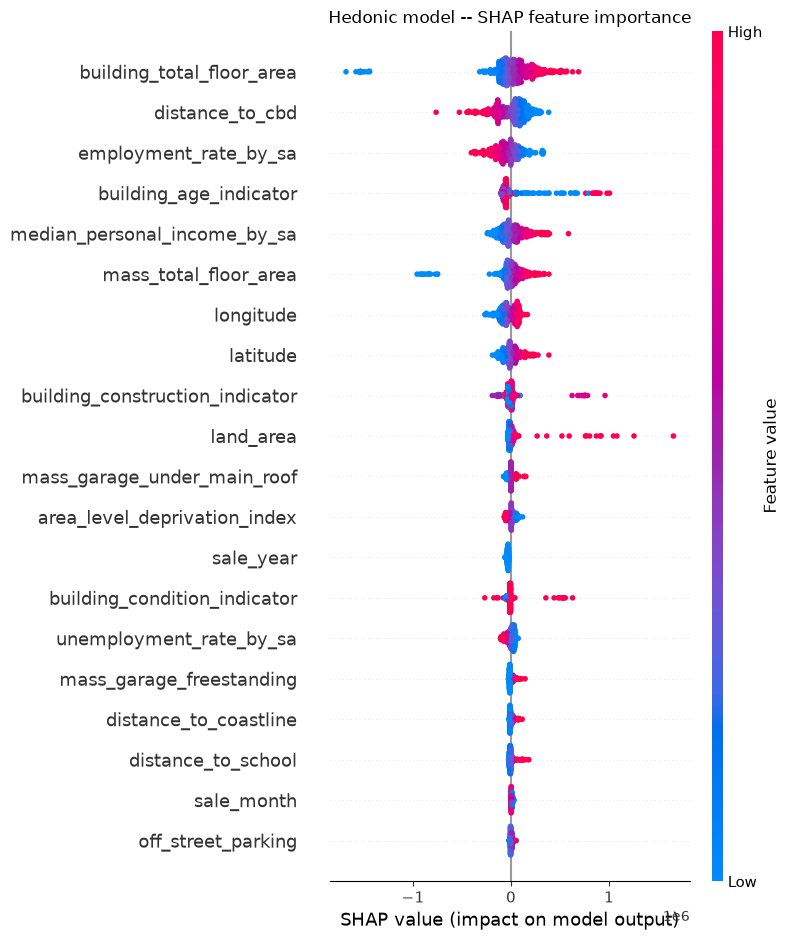

In [9]:
import shap
import matplotlib.pyplot as plt

shap_fold = folds[-1]
shap_sample = shap_fold["X_test"].sample(n=500, random_state=42)
background = shap_fold["X_train"].sample(n=100, random_state=42)
predict5 = hedonic_predictor(h5)

start = time.time()
hed_shap = shap.PermutationExplainer(predict5, background)(shap_sample, silent=True)
print(f"SHAP done in {time.time() - start:.0f}s")

shap.summary_plot(hed_shap.values, shap_sample, max_display=20, show=False)
plt.title("Hedonic model -- SHAP feature importance")
plt.tight_layout()
plt.show()

In [10]:
hed_share = pd.Series(np.abs(hed_shap.values).mean(axis=0), index=FEATURE_COLS)
hed_table = pd.DataFrame({
    "mean |SHAP| ($)": hed_share.round(0),
    "% of total": (hed_share / hed_share.sum() * 100).round(1),
}).sort_values("% of total", ascending=False)
hed_table["rank"] = range(1, len(hed_table) + 1)
hed_table

,mean |SHAP| ($),% of total,rank
building_total_floor_area,153187.0,13.7,1
distance_to_cbd,121181.0,10.8,2
employment_rate_by_sa,97443.0,8.7,3
building_age_indicator,96673.0,8.6,4
median_personal_income_by_sa,94456.0,8.4,5
mass_total_floor_area,85980.0,7.7,6
longitude,65095.0,5.8,7
latitude,57946.0,5.2,8
building_construction_indicator,42503.0,3.8,9
land_area,39574.0,3.5,10


## 8. Explaining one house

Same as `remake_train.ipynb` section 7 and `remake_nn.ipynb` section 8:
the model is fitted on fold 5's training period, and the **same 10 unseen
houses** (same seed) are predicted, so all models can be compared on the same
property. Set `HOUSE` to pick which one to explain.

In [11]:
HOUSE = 1  # which house from the table below to explain (1-10)

house_fold = folds[-1]
predict_house = hedonic_predictor(fit_hedonic(house_fold["X_train"], house_fold["y_train"]))

houses = house_fold["X_test"].sample(n=10, random_state=7)  # same 10 as remake_train.ipynb
house_actual = pd.Series(house_fold["y_test"], index=house_fold["X_test"].index).loc[houses.index]
house_pred = pd.Series(predict_house(houses), index=houses.index)

### 8.1 Readable values and addresses

In [12]:
raw = pd.read_parquet(
    "./cache/dvrs_with_team_external.parquet",
    columns=["valuation_id_concat", "sale_date", "sale_price_gross",
             "situation_number", "additional_situation_number", "situation_name"],
)
raw["sale_price_gross"] = pd.to_numeric(raw["sale_price_gross"], errors="coerce")
raw["sale_date_parsed"] = pd.to_datetime(raw["sale_date"].astype(str).str.zfill(8), format="%d%m%Y")
raw["address"] = (
    raw["situation_number"].astype(str)
    + raw["additional_situation_number"].fillna("").astype(str)
    + " " + raw["situation_name"].fillna("").astype(str).str.title()
)
addresses = (
    raw.drop_duplicates(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])
    .set_index(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])["address"]
)
key = pd.MultiIndex.from_frame(df.loc[houses.index, ["valuation_id_concat", "sale_date_parsed", "sale_price_gross"]])
house_address = pd.Series(addresses.reindex(key).values, index=houses.index).fillna("(address not found)")


def readable_row(i):
    """Feature values for one house in human units (from the unprocessed data)."""
    r = df.loc[i]
    age = str(r["building_age_indicator"])
    return {
        "property_type": r["property_type"],
        "building_age_indicator": f"{age}0s" if age.isdigit() else age,
        "building_condition_indicator": r["building_condition_indicator"],
        "building_construction_indicator": r["building_construction_indicator"],
        "noise_category_combination": r["noise_category_combination"].replace("_", " "),
        "in_flood_plain": "yes" if r["in_flood_plain"] else "no",
        "land_area": f"{np.expm1(r['land_area']) * 10_000:,.0f} sqm",  # stored in hectares
        "building_total_floor_area": f"{np.expm1(r['building_total_floor_area']):,.0f} sqm",
        "mass_total_floor_area": f"{np.expm1(r['mass_total_floor_area']):,.0f} sqm",
        "off_street_parking": f"{r['off_street_parking']:.0f}",
        "mass_garage_under_main_roof": f"{r['mass_garage_under_main_roof']:.0f}",
        "mass_garage_freestanding": f"{r['mass_garage_freestanding']:.0f}",
        "latitude": f"{r['latitude']:.4f}",
        "longitude": f"{r['longitude']:.4f}",
        "distance_to_cbd": f"{r['distance_to_cbd'] / 1000:.1f} km",
        "walk_supermarket_network_m": "n/a" if pd.isna(r["walk_supermarket_network_m"]) else f"{np.expm1(r['walk_supermarket_network_m']):,.0f} m",
        "walk_bus_stop_network_m": "n/a" if pd.isna(r["walk_bus_stop_network_m"]) else f"{np.expm1(r['walk_bus_stop_network_m']):,.0f} m",
        "distance_to_school": f"{r['distance_to_school']:,.0f} m",
        "area_level_deprivation_index": f"{r['area_level_deprivation_index']:.0f} of 10",
        "median_personal_income_by_sa": f"${r['median_personal_income_by_sa']:,.0f}",
        "employment_rate_by_sa": f"{r['employment_rate_by_sa']:.0f}%",
        "unemployment_rate_by_sa": f"{r['unemployment_rate_by_sa']:.1f}%",
        "population_counts_by_sa": f"{r['population_counts_by_sa']:,.0f}",
        "population_density": f"{r['population_density']:,.0f} per sq km",
        "distance_to_coastline": f"{r['distance_to_coastline']:,.0f} m",
        "building_consents": f"{r['building_consents']:.0f}",
        "sale_year": f"{r['sale_year']:.0f}",
        "sale_month": f"{r['sale_month']:.0f}",
        "sale_quarter": f"Q{r['sale_quarter']:.0f}",
    }


readable = pd.DataFrame([readable_row(i) for i in houses.index], index=houses.index)[FEATURE_COLS]

### 8.2 The 10 houses at a glance

In [13]:
house_summary = pd.DataFrame({
    "address": house_address,
    "sale_date": df.loc[houses.index, "sale_date_parsed"].dt.date,
    "actual_price": house_actual.map("${:,.0f}".format),
    "predicted_price": house_pred.map("${:,.0f}".format),
    "error": ((house_pred - house_actual) / house_actual * 100).map("{:+.1f}%".format),
})
house_summary.index = range(1, len(house_summary) + 1)
house_summary.index.name = "house"
house_summary

,address,sale_date,actual_price,predicted_price,error
house,,,,,
1,119 Waimumu Rd,2026-05-15,"$1,085,000","$874,841",-19.4%
2,8/3 Park Rise,2026-05-20,"$1,495,000","$1,398,115",-6.5%
3,40E Estuary Rd,2026-02-02,"$690,000","$743,030",+7.7%
4,15A Clifton Rd,2026-05-06,"$2,755,000","$2,447,043",-11.2%
5,182 Glamorgan Dr,2026-04-24,"$835,000","$1,073,504",+28.6%
6,3 Uma Gr,2026-04-15,"$765,000","$949,356",+24.1%
7,12B Rewi St,2026-06-01,"$1,285,000","$1,323,443",+3.0%
8,10 Pecan Pl,2026-02-19,"$835,000","$1,038,697",+24.4%
9,10 Wairua Pl,2026-06-21,"$680,000","$605,987",-10.9%


### 8.3 Why the model gave this price

Contributions are grouped into five themes for the summary (a theme's
contribution is the sum of its features'). The waterfall chart shows the 10
largest individual features, the rest combined into one bar; red raises the
price, blue lowers it, and the dotted / solid / dashed lines mark the
average, predicted and actual price.

These explain what the **model** learned from past sales -- they are not
proof that a feature causes a price change in the market.

House 1: 119 Waimumu Rd  (sold 2026-05-15)
  Predicted $874,841   actual $1,085,000   error -19.4%
  Start from the model's average predicted price: $1,140,086
       -$154,251  Neighbourhood    mainly median_personal_income_by_sa = $41,200 (-$60,469), area_level_deprivation_index = 9 of 10 (-$47,092)
        -$60,684  Location         mainly longitude = 174.6163 (-$109,493), distance_to_cbd = 13.2 km (+$54,799)
        -$28,378  Market & timing  mainly sale_year = 2026 (-$29,619), sale_month = 5 (+$4,338)
        -$26,908  House & land     mainly building_condition_indicator = FA (-$49,889), mass_garage_under_main_roof = 0 (-$43,776)
         +$4,977  Hazards          mainly noise_category_combination = outside current overlay (+$3,408), in_flood_plain = no (+$1,569)
  = predicted $874,841
  In short: the biggest push UP is distance_to_cbd (13.2 km, +$54,799); the biggest push DOWN is longitude (174.6163, -$109,493).


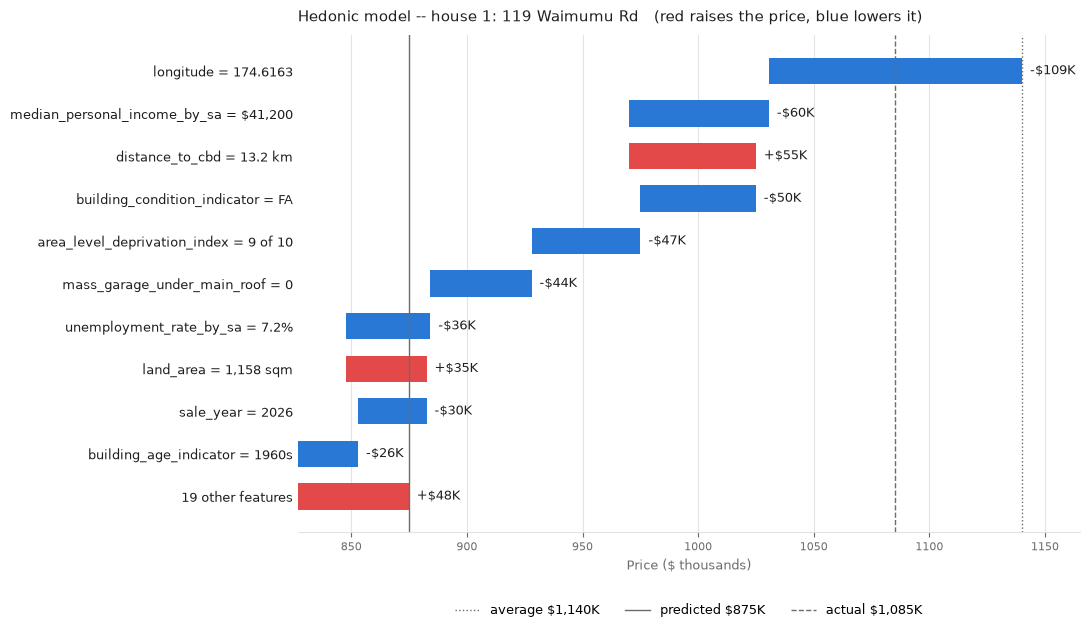

In [14]:
import shap
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

THEMES = {
    "Location": ["latitude", "longitude", "distance_to_cbd", "distance_to_coastline",
                 "distance_to_school", "walk_supermarket_network_m", "walk_bus_stop_network_m"],
    "Neighbourhood": ["area_level_deprivation_index", "median_personal_income_by_sa",
                      "employment_rate_by_sa", "unemployment_rate_by_sa",
                      "population_counts_by_sa", "population_density"],
    "House & land": ["land_area", "building_total_floor_area", "mass_total_floor_area",
                     "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
                     "building_age_indicator", "building_condition_indicator",
                     "building_construction_indicator", "property_type"],
    "Hazards": ["in_flood_plain", "noise_category_combination"],
    "Market & timing": ["building_consents", "sale_year", "sale_month", "sale_quarter"],
}
assert sorted(sum(THEMES.values(), [])) == sorted(FEATURE_COLS), "every feature must be in exactly one theme"

UP, DOWN = "#e34948", "#2a78d6"          # raises / lowers the price
INK, INK_MUTED, GRID = "#1f1f1e", "#6b6b68", "#e4e3df"


def money(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):,.0f}"


def mpl(s):
    # A bare "$" switches matplotlib into maths formatting, so escape it.
    return s.replace("$", "\\$")


i = houses.index[HOUSE - 1]
background = house_fold["X_train"].sample(n=100, random_state=42)
house_expl = shap.PermutationExplainer(predict_house, background)(houses.loc[[i]], silent=True)
contrib = pd.Series(house_expl.values[0], index=FEATURE_COLS)
base_value = float(house_expl.base_values[0])

# SHAP is additive: average + contributions must equal the prediction.
assert np.isclose(base_value + contrib.sum(), house_pred[i], rtol=1e-3)

themes = pd.Series({t: contrib[cols].sum() for t, cols in THEMES.items()})
err = (house_pred[i] - house_actual[i]) / house_actual[i] * 100

# Plain-English summary
print(f"House {HOUSE}: {house_address[i]}  (sold {df.loc[i, 'sale_date_parsed'].date()})")
print(f"  Predicted ${house_pred[i]:,.0f}   actual ${house_actual[i]:,.0f}   error {err:+.1f}%")
print(f"  Start from the model's average predicted price: ${base_value:,.0f}")
for theme, value in themes.sort_values(key=abs, ascending=False).items():
    top = contrib[THEMES[theme]].sort_values(key=abs, ascending=False).head(2)
    detail = ", ".join(f"{f} = {readable.loc[i, f]} ({money(v)})" for f, v in top.items())
    print(f"    {money(value):>12}  {theme:<16} mainly {detail}")
print(f"  = predicted ${house_pred[i]:,.0f}")
up, down = contrib.idxmax(), contrib.idxmin()
print(f"  In short: the biggest push UP is {up} ({readable.loc[i, up]}, {money(contrib[up])}); "
      f"the biggest push DOWN is {down} ({readable.loc[i, down]}, {money(contrib[down])}).")

# Waterfall: bars run from the average price to the prediction, one step per feature.
order = contrib.abs().sort_values(ascending=False).index
steps = list(contrib[order[:10]].items()) + [(f"{len(order) - 10} other features", contrib[order[10:]].sum())]
labels = [f"{f} = {readable.loc[i, f]}" if f in readable.columns else f for f, _ in steps]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(steps) + 1.8))
level = base_value
for row, (_, v) in enumerate(steps):
    ax.barh(row, v / 1000, left=level / 1000, height=0.62, color=UP if v >= 0 else DOWN)
    ax.text(max(level, level + v) / 1000, row, mpl(f"  {'+' if v >= 0 else '-'}${abs(v) / 1000:,.0f}K"),
            va="center", ha="left", fontsize=9, color=INK)
    level += v

reference = [
    (base_value, f"average ${base_value / 1000:,.0f}K", ":"),
    (house_pred[i], f"predicted ${house_pred[i] / 1000:,.0f}K", "-"),
    (house_actual[i], f"actual ${house_actual[i] / 1000:,.0f}K", "--"),
]
for value, _, style in reference:
    ax.axvline(value / 1000, color=INK_MUTED, linestyle=style, linewidth=1)
ax.legend(
    handles=[Line2D([], [], color=INK_MUTED, linestyle=s, linewidth=1, label=mpl(t)) for _, t, s in reference],
    loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9,
)

ax.set_yticks(range(len(steps)))
ax.set_yticklabels([mpl(l) for l in labels], fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlabel(mpl("Price ($ thousands)"), fontsize=9, color=INK_MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", colors=INK_MUTED, labelsize=8)
ax.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
left, right = ax.get_xlim()
ax.set_xlim(left, right + (right - left) * 0.08)  # room for the last label
ax.set_title(f"Hedonic model -- house {HOUSE}: {house_address[i]}   (red raises the price, blue lowers it)",
             loc="left", fontsize=11, color=INK, pad=10)
plt.tight_layout()
plt.show()